# Tabular Data Engineering, EDA & Product Model
Author: Patrick Tuyizere

This notebook builds a recommendation model pipeline. First the system checks the user's face. Second, it verifies their voice. Once both checks pass, it predicts which product the user is most likely to buy based on their social media activity and past purchases.

## 1. Load Datasets And Inspect Structure

We load the `customer_social_profiles` and `customer_transactions` datasets and check their rows, columns, and data types to see how they are structured before cleaning.

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json

from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, log_loss, classification_report, ConfusionMatrixDisplay

In [3]:
from google.colab import drive

drive.mount("/content/drive/")

DATASET_ROOT = "/content/drive/MyDrive/ml_pipeline_formative2_dataset"

social_df = pd.read_csv(DATASET_ROOT + "/customer_social_profiles.csv")
trans_df = pd.read_csv(DATASET_ROOT + "/customer_transactions.csv")

display(social_df.head(3))
print(trans_df.info())

Mounted at /content/drive/


,customer_id_new,social_media_platform,engagement_score,purchase_interest_score,review_sentiment
0,A178,LinkedIn,74,4.9,Positive
1,A190,Twitter,82,4.8,Neutral
2,A150,Facebook,96,1.6,Positive


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   customer_id_legacy  150 non-null    int64  
 1   transaction_id      150 non-null    int64  
 2   purchase_amount     150 non-null    int64  
 3   purchase_date       150 non-null    object 
 4   product_category    150 non-null    object 
 5   customer_rating     140 non-null    float64
dtypes: float64(1), int64(3), object(2)
memory usage: 7.2+ KB
None


## 2. Data Cleaning And Merge

The two datasets list customer IDs differently (`A101` vs. `101`). We remove the letter 'A' so the IDs match, remove duplicate rows, fill missing values and, merge both tables using an inner join.



In [4]:
print("Social Profiles Missing Values:\n", social_df.isnull().sum())
print("\nTransactions Missing Values:\n", trans_df.isnull().sum())

social_df = social_df.drop_duplicates().copy()
trans_df = trans_df.drop_duplicates().copy()

if 'customer_id_new' in social_df.columns:
    social_df['customer_id'] = (
        social_df['customer_id_new']
        .astype(str)
        .str.replace('A', '', regex=False)
        .str.strip()
        .astype(int)
    )
else:
    social_df['customer_id'] = (
        social_df['customer_id']
        .astype(str)
        .str.replace('A', '', regex=False)
        .str.strip()
        .astype(int)
    )

if 'customer_id_legacy' in trans_df.columns:
    trans_df['customer_id'] = trans_df['customer_id_legacy'].astype(int)
else:
    trans_df['customer_id'] = trans_df['customer_id'].astype(int)

trans_df['purchase_date'] = pd.to_datetime(trans_df['purchase_date'], errors='coerce')

def get_mode(series):
    modes = series.dropna().mode()
    return modes.iloc[0] if not modes.empty else "Unknown"

social_collapsed = social_df.groupby('customer_id', as_index=False).agg(
    engagement_score=('engagement_score', 'mean'),
    purchase_interest_score=('purchase_interest_score', 'mean'),
    social_media_platform=('social_media_platform', get_mode),
    social_platform_count=('social_media_platform', 'nunique'),
    review_sentiment=('review_sentiment', get_mode)
)

print(f"\nCollapsed Social Profiles from {len(social_df)} rows to {len(social_collapsed)} unique customers.")

# merge and validate unmatched transactions
total_tx = len(trans_df)
merged_df = pd.merge(trans_df, social_collapsed, on='customer_id', how='inner')

if 'customer_id_legacy' in merged_df.columns:
    merged_df.drop(columns=['customer_id_legacy'], inplace=True)

matched_tx = len(merged_df)
unmatched_tx = total_tx - matched_tx

print("\n=== MERGE VALIDATION CHECKS ===")
print(f"Total transactions before merge:      {total_tx}")
print(f"Matched transactions (inner join):    {matched_tx}")
print(f"Unmatched transactions (no social):   {unmatched_tx} dropped")
print(f"Is transaction_id 100% unique?:       {merged_df['transaction_id'].is_unique}")
print(f"Post-merge missing values:            {merged_df.isnull().sum().sum()}")

# Save clean merged dataset (1 row per transaction)
merged_df.to_csv("merged_dataset.csv", index=False)
print(f"\nSaved clean merged dataset to: {'merged_dataset.csv'}")
display(merged_df.head(3))

Social Profiles Missing Values:
 customer_id_new            0
social_media_platform      0
engagement_score           0
purchase_interest_score    0
review_sentiment           0
dtype: int64

Transactions Missing Values:
 customer_id_legacy     0
transaction_id         0
purchase_amount        0
purchase_date          0
product_category       0
customer_rating       10
dtype: int64

Collapsed Social Profiles from 150 rows to 84 unique customers.

=== MERGE VALIDATION CHECKS ===
Total transactions before merge:      150
Matched transactions (inner join):    117
Unmatched transactions (no social):   33 dropped
Is transaction_id 100% unique?:       True
Post-merge missing values:            8

Saved clean merged dataset to: merged_dataset.csv


,transaction_id,purchase_amount,purchase_date,product_category,customer_rating,customer_id,engagement_score,purchase_interest_score,social_media_platform,social_platform_count,review_sentiment
0,1001,408,2024-01-01,Sports,2.3,151,71.666667,2.166667,Twitter,2,Neutral
1,1002,332,2024-01-02,Electronics,4.2,192,60.000000,4.300000,Instagram,1,Positive
2,1003,442,2024-01-03,Electronics,2.1,114,87.000000,4.800000,Facebook,1,Negative


## 3. Data Analysis And Visualizations

=== NUMERICAL SUMMARY STATISTICS ===


,count,mean,min,25%,50%,75%,max,std
transaction_id,117.0,1074.25641,1001.0,1036.0,1073.0,1113.0,1150.0,44.27328
purchase_amount,117.0,287.905983,62.0,183.0,280.0,397.0,495.0,120.084165
purchase_date,117,2024-03-14 06:09:13.846153728,2024-01-01 00:00:00,2024-02-05 00:00:00,2024-03-13 00:00:00,2024-04-22 00:00:00,2024-05-29 00:00:00,NaN
customer_rating,109.0,3.116514,1.0,2.1,3.3,4.2,5.0,1.23884
customer_id,117.0,147.91453,100.0,117.0,146.0,180.0,199.0,32.288722
engagement_score,117.0,74.154558,50.0,66.5,77.0,83.0,99.0,12.67478
purchase_interest_score,117.0,3.077208,1.0,2.666667,3.133333,3.7,4.8,1.039644
social_platform_count,117.0,1.598291,1.0,1.0,1.0,2.0,4.0,0.731788



=== CATEGORICAL SUMMARY STATISTICS ===


,count,unique,top,freq
product_category,117,5,Sports,28
social_media_platform,117,5,Facebook,32
review_sentiment,117,3,Positive,44


/tmp/ipykernel_661/2409595034.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=merged_df, x='product_category', y='purchase_amount', palette='Set2', ax=axes[0, 1])


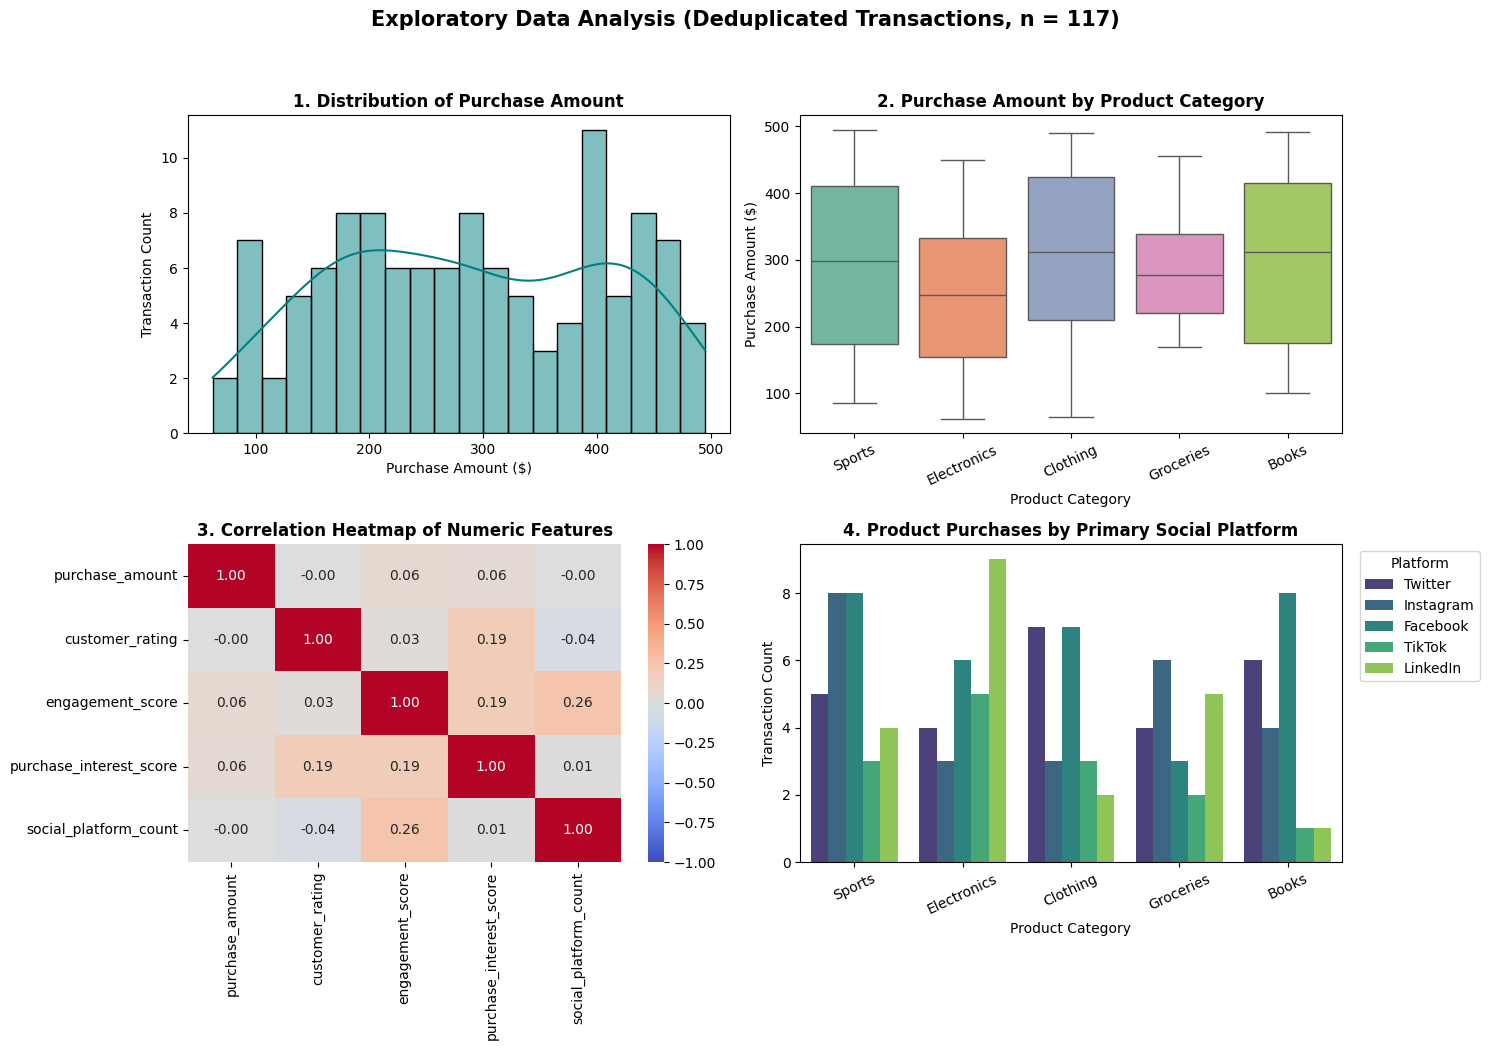

In [5]:
print("=== NUMERICAL SUMMARY STATISTICS ===")
display(merged_df.describe().T)

print("\n=== CATEGORICAL SUMMARY STATISTICS ===")
display(merged_df.describe(include=['object']).T)

fig, axes = plt.subplots(2, 2, figsize=(15, 11))
fig.suptitle('Exploratory Data Analysis (Deduplicated Transactions, n = 117)', fontsize=15, fontweight='bold')

# Plot 1: Distribution of Purchase Amount
sns.histplot(merged_df['purchase_amount'], kde=True, ax=axes[0, 0], color='teal', bins=20)
axes[0, 0].set_title('1. Distribution of Purchase Amount', fontweight='bold')
axes[0, 0].set_xlabel('Purchase Amount ($)')
axes[0, 0].set_ylabel('Transaction Count')

# Plot 2: Outliers by Product Category
sns.boxplot(data=merged_df, x='product_category', y='purchase_amount', palette='Set2', ax=axes[0, 1])
axes[0, 1].set_title('2. Purchase Amount by Product Category', fontweight='bold')
axes[0, 1].set_xlabel('Product Category')
axes[0, 1].set_ylabel('Purchase Amount ($)')
axes[0, 1].tick_params(axis='x', rotation=25)

# Plot 3: Correlation
num_cols = ['purchase_amount', 'customer_rating', 'engagement_score', 'purchase_interest_score', 'social_platform_count']
corr_matrix = merged_df[num_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=axes[1, 0])
axes[1, 0].set_title('3. Correlation Heatmap of Numeric Features', fontweight='bold')

# Plot 4: Product Category by Primary Social Media Platform
sns.countplot(data=merged_df, x='product_category', hue='social_media_platform', palette='viridis', ax=axes[1, 1])
axes[1, 1].set_title('4. Product Purchases by Primary Social Platform', fontweight='bold')
axes[1, 1].set_xlabel('Product Category')
axes[1, 1].set_ylabel('Transaction Count')
axes[1, 1].tick_params(axis='x', rotation=25)
axes[1, 1].legend(title='Platform', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

## 4. Feature Engineering And Grouped Split
Since one individual customer may have several social profile records or transactions, combining customer-level behavior data along with other time based and interaction data is extremely helpful for improving prediction accuracy.

In [7]:

fe_df = merged_df.copy()

# 1. Create visit-time features (when the user visits the site)
fe_df['purchase_month'] = fe_df['purchase_date'].dt.month
fe_df['purchase_dayofweek'] = fe_df['purchase_date'].dt.dayofweek
fe_df['is_weekend'] = fe_df['purchase_dayofweek'].isin([5, 6]).astype(int)
fe_df['engagement_to_interest_ratio'] = (
    fe_df['engagement_score'] / (fe_df['purchase_interest_score'] + 1e-5)
)

# 2. GroupShuffleSplit on customer_id
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(fe_df, y=fe_df['product_category'], groups=fe_df['customer_id']))

train_df = fe_df.iloc[train_idx].copy()
test_df = fe_df.iloc[test_idx].copy()

print(f"Train rows: {len(train_df)} | Test rows: {len(test_df)}")
print(f"Shared transaction_ids between train and test: {len(set(train_df['transaction_id']) & set(test_df['transaction_id']))}")
print(f"Shared customer_ids between train and test:    {len(set(train_df['customer_id']) & set(test_df['customer_id']))}")

# 3. Compute historical customer aggregates inside the training fold
train_cust_agg = train_df.groupby('customer_id', as_index=False).agg(
    cust_tx_count=('transaction_id', 'count'),
    cust_avg_spend=('purchase_amount', 'mean')
)

default_tx_count = train_cust_agg['cust_tx_count'].median()
default_avg_spend = train_df['purchase_amount'].mean()

train_df = pd.merge(train_df, train_cust_agg, on='customer_id', how='left')
test_df = pd.merge(test_df, train_cust_agg, on='customer_id', how='left')

test_df['cust_tx_count'] = test_df['cust_tx_count'].fillna(default_tx_count)
test_df['cust_avg_spend'] = test_df['cust_avg_spend'].fillna(default_avg_spend)

# 4. Keep valid visit-time features only
target_col = 'product_category'
post_purchase_and_id_cols = [
    target_col,
    'transaction_id',
    'customer_id',
    'purchase_date',
    'purchase_amount',
    'customer_rating',
    'review_sentiment'
]

feature_cols = [c for c in train_df.columns if c not in post_purchase_and_id_cols]
print("\nVisit-time features used for modeling:")
print(feature_cols)

Train rows: 95 | Test rows: 22
Shared transaction_ids between train and test: 0
Shared customer_ids between train and test:    0

Visit-time features used for modeling:
['engagement_score', 'purchase_interest_score', 'social_media_platform', 'social_platform_count', 'purchase_month', 'purchase_dayofweek', 'is_weekend', 'engagement_to_interest_ratio', 'cust_tx_count', 'cust_avg_spend']


## 5 Train And Evaluate Product Recommendation Model
Below, we train and compare Logistic Regression, Random Forest, and Gradient Boosting, then export the best pipeline.

=== PRODUCT MODEL COMPARISON ===


,Model,Accuracy,Random Chance Baseline,Weighted F1-Score,Log Loss
1,Random Forest,0.3182,0.2,0.2934,1.7182
0,Logistic Regression,0.1818,0.2,0.1336,1.9496
2,Gradient Boosting,0.1818,0.2,0.1164,2.1610



Selected Model: Random Forest

Classification Report on Held-Out Test Set:
              precision    recall  f1-score   support

       Books       0.00      0.00      0.00         5
    Clothing       0.33      1.00      0.50         1
 Electronics       0.25      0.40      0.31         5
   Groceries       1.00      0.50      0.67         4
      Sports       0.22      0.29      0.25         7

    accuracy                           0.32        22
   macro avg       0.36      0.44      0.34        22
weighted avg       0.32      0.32      0.29        22



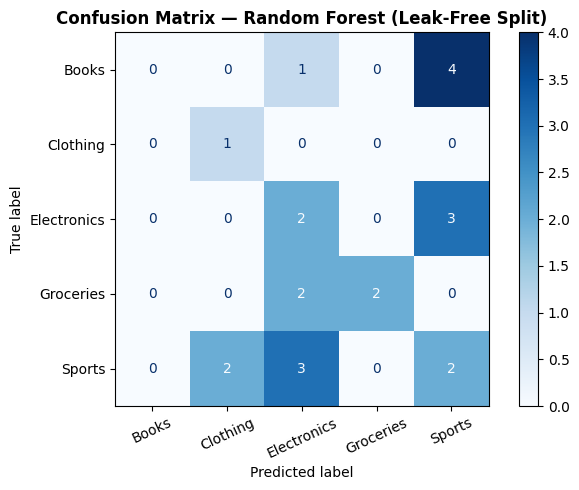

In [9]:
X_train = train_df[feature_cols]
y_train = train_df[target_col].astype(str)

X_test = test_df[feature_cols]
y_test = test_df[target_col].astype(str)

num_features = X_train.select_dtypes(include=[np.number]).columns.tolist()
cat_features = X_train.select_dtypes(include=['object', 'category']).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features)
    ]
)

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=6, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, learning_rate=0.05, max_depth=3, random_state=42)
}

results = []
trained_pipelines = {}

for name, clf in models.items():
    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', clf)
    ])
    pipe.fit(X_train, y_train)

    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)

    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)
    loss = log_loss(y_test, y_prob, labels=pipe.classes_)

    results.append({
        'Model': name,
        'Accuracy': round(acc, 4),
        'Random Chance Baseline': 0.2000,
        'Weighted F1-Score': round(f1, 4),
        'Log Loss': round(loss, 4)
    })
    trained_pipelines[name] = pipe

results_df = pd.DataFrame(results).sort_values(by='Log Loss', ascending=True)
print("=== PRODUCT MODEL COMPARISON ===")
display(results_df)

# Select model with lowest Log Loss / best generalization
best_model_name = results_df.iloc[0]['Model']
best_pipeline = trained_pipelines[best_model_name]
best_preds = best_pipeline.predict(X_test)

print(f"\nSelected Model: {best_model_name}")
print("\nClassification Report on Held-Out Test Set:")
print(classification_report(y_test, best_preds, zero_division=0))

fig, ax = plt.subplots(figsize=(7, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_preds,
    display_labels=best_pipeline.classes_,
    cmap='Blues',
    xticks_rotation=25,
    ax=ax
)
ax.set_title(f'Confusion Matrix — {best_model_name} (Leak-Free Split)', fontweight='bold')
plt.grid(False)
plt.tight_layout()
plt.show()

## 6. Exporting Artifact


In [12]:
import pathlib

model_path = "product_model.joblib"
joblib.dump(best_pipeline, model_path)
print(f"1. Saved Pipeline object directly to: {model_path}")


latest_visit = (
    fe_df.sort_values('purchase_date')
    .groupby('customer_id', as_index=False)
    .last()
)

latest_visit = pd.merge(latest_visit, train_cust_agg, on='customer_id', how='left')
latest_visit['cust_tx_count'] = latest_visit['cust_tx_count'].fillna(default_tx_count)
latest_visit['cust_avg_spend'] = latest_visit['cust_avg_spend'].fillna(default_avg_spend)

inference_cols = ['customer_id'] + feature_cols
customer_inference_df = latest_visit[inference_cols].sort_values('customer_id').reset_index(drop=True)

inference_path = "customer_inference.csv"
customer_inference_df.to_csv(inference_path, index=False)
print(f"2. Saved customer inference table ({customer_inference_df.shape[0]} customers, no target) to: {inference_path}")
display(customer_inference_df.head(3))

metadata_path = "model_metadata.json"
if pathlib.Path(metadata_path).exists():
    with open(metadata_path, "r", encoding="utf-8") as f:
        metadata = json.load(f)
else:
    metadata = {}

metadata.setdefault("product", {})
metadata["product"]["model_name"] = best_model_name
metadata["product"]["feature_columns"] = feature_cols
metadata["product"]["classes"] = best_pipeline.classes_.tolist()

with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

print(f"3. Updated {metadata_path} with product.feature_columns:")
print(json.dumps(metadata["product"], indent=2))

sample_row = customer_inference_df.iloc[[0]][metadata["product"]["feature_columns"]]
loaded_pipe = joblib.load(model_path)
sample_pred = loaded_pipe.predict(sample_row)[0]
sample_conf = loaded_pipe.predict_proba(sample_row).max() * 100
print(f"\nCLI Check -> Customer {customer_inference_df.iloc[0]['customer_id']} predicted product: {sample_pred} ({sample_conf:.1f}% confidence)")

1. Saved Pipeline object directly to: product_model.joblib
2. Saved customer inference table (61 customers, no target) to: customer_inference.csv


,customer_id,engagement_score,purchase_interest_score,social_media_platform,social_platform_count,purchase_month,purchase_dayofweek,is_weekend,engagement_to_interest_ratio,cust_tx_count,cust_avg_spend
0,100,77.0,4.4,Instagram,2,5,6,1,17.499960,2.0,287.536842
1,101,68.0,1.0,Twitter,1,3,2,0,67.999320,4.0,254.000000
2,102,51.0,4.8,LinkedIn,1,5,5,1,10.624978,3.0,189.666667


3. Updated model_metadata.json with product.feature_columns:
{
  "model_name": "Random Forest",
  "feature_columns": [
    "engagement_score",
    "purchase_interest_score",
    "social_media_platform",
    "social_platform_count",
    "purchase_month",
    "purchase_dayofweek",
    "is_weekend",
    "engagement_to_interest_ratio",
    "cust_tx_count",
    "cust_avg_spend"
  ],
  "classes": [
    "Books",
    "Clothing",
    "Electronics",
    "Groceries",
    "Sports"
  ]
}

CLI Check -> Customer 100 predicted product: Sports (31.6% confidence)
